# NeuroAdapt — BraTS2020 HDF5 Exploration
Kaggle-ready notebook for `volume_<id>_slice_<index>.h5` datasets. **This is 2D slice data, not original NIfTI volumes.**

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, h5py, re
from pathlib import Path
from IPython.display import display
print("h5py:", h5py.__version__)

h5py: 3.14.0


## 1. Find the attached HDF5 dataset

In [4]:
DATA_ROOT = Path('/kaggle/input')
files = sorted(DATA_ROOT.rglob('*.h5'))
print(f'Found {len(files):,} HDF5 files')
for p in files[:5]: print(p)
if not files: raise FileNotFoundError('No .h5 files. Attach the awsaf49 BraTS2020 training dataset using Add Input.')

Found 57,195 HDF5 files
/kaggle/input/datasets/awsaf49/brats2020-training-data/BraTS2020_training_data/content/data/volume_100_slice_0.h5
/kaggle/input/datasets/awsaf49/brats2020-training-data/BraTS2020_training_data/content/data/volume_100_slice_1.h5
/kaggle/input/datasets/awsaf49/brats2020-training-data/BraTS2020_training_data/content/data/volume_100_slice_10.h5
/kaggle/input/datasets/awsaf49/brats2020-training-data/BraTS2020_training_data/content/data/volume_100_slice_100.h5
/kaggle/input/datasets/awsaf49/brats2020-training-data/BraTS2020_training_data/content/data/volume_100_slice_101.h5


## 2. Inspect the actual HDF5 structure
The dataset is expected to have an `image` array and a `mask` array. We inspect keys and shapes before processing.

In [5]:
def inspect_h5(path):
    with h5py.File(path, 'r') as f:
        def describe(name, obj):
            if isinstance(obj, h5py.Dataset): print(f'{name}: shape={obj.shape}, dtype={obj.dtype}')
        f.visititems(describe)
inspect_h5(files[0])

image: shape=(240, 240, 4), dtype=float64
mask: shape=(240, 240, 3), dtype=uint8


## 3. Load a slice and normalize its axis order
The common awsaf49 dataset uses `image` shape `(H, W, 4)` and `mask` shape `(H, W, 3)`. Channel order is **usually** T1, T1ce, T2, FLAIR; verify with the dataset documentation. Mask channels generally represent tumor subregions, not the original integer BraTS labels.

In [6]:
MODALITIES = ['T1', 'T1ce', 'T2', 'FLAIR']

def load_slice(path):
    with h5py.File(path, 'r') as f:
        if 'image' not in f or 'mask' not in f:
            raise KeyError(f'{path.name}: expected keys image and mask, found {list(f.keys())}')
        image = f['image'][:]
        mask = f['mask'][:]
    if image.ndim != 3: raise ValueError(f'Unexpected image shape: {image.shape}')
    if image.shape[-1] == 4:
        pass
    elif image.shape[0] == 4:
        image = np.moveaxis(image, 0, -1)
    else: raise ValueError(f'Cannot identify four image channels: {image.shape}')
    if mask.ndim == 2: mask = mask[..., None]
    elif mask.ndim == 3 and mask.shape[:2] != image.shape[:2] and mask.shape[1:] == image.shape[:2]:
        mask = np.moveaxis(mask, 0, -1)
    if mask.shape[:2] != image.shape[:2]: raise ValueError(f'Image/mask mismatch: {image.shape}, {mask.shape}')
    return image, mask

image, mask = load_slice(files[0])
print('Image:', image.shape, image.dtype, 'Mask:', mask.shape, mask.dtype)
print('Mask channel values:', [np.unique(mask[...,i])[:12] for i in range(mask.shape[-1])])

Image: (240, 240, 4) float64 Mask: (240, 240, 3) uint8
Mask channel values: [array([0], dtype=uint8), array([0], dtype=uint8), array([0], dtype=uint8)]


## 4. Select a slice containing tumor
Find a useful example among the first 500 slices (configurable).

In [7]:
SCAN_LIMIT = min(500, len(files))
selected = files[0]
for p in files[:SCAN_LIMIT]:
    with h5py.File(p, 'r') as f:
        if 'mask' in f and np.any(f['mask'][:] > 0):
            selected = p
            break
image, mask = load_slice(selected)
print('Selected:', selected.name, '| tumor-positive pixels:', int(np.any(mask > 0, axis=-1).sum()))

Selected: volume_100_slice_100.h5 | tumor-positive pixels: 1111


## 5. Display the four MRI modalities

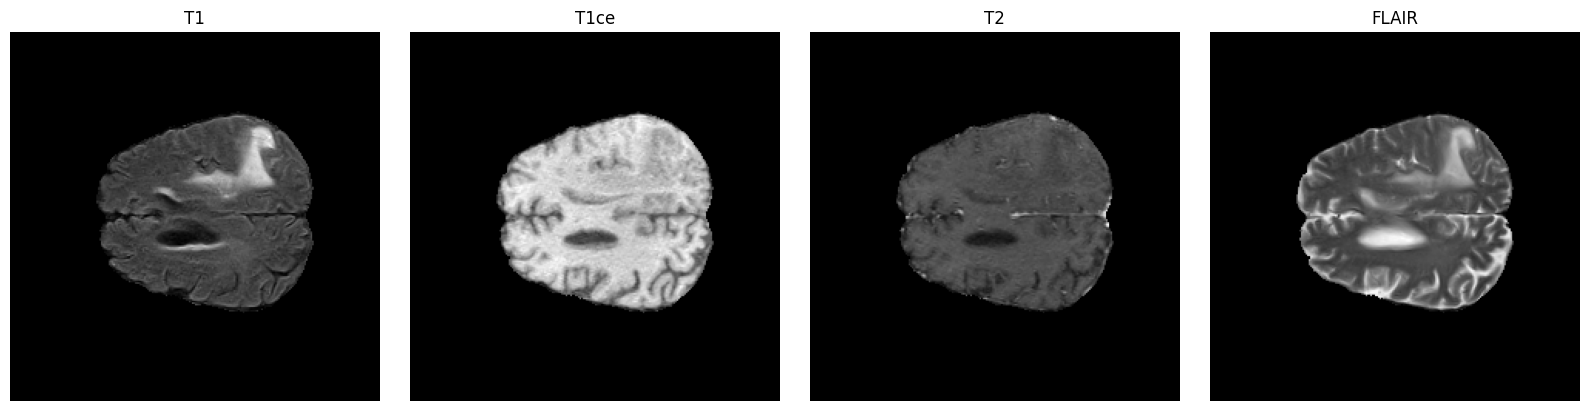

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
for i, ax in enumerate(axs):
    ax.imshow(image[..., i], cmap='gray')
    ax.set_title(MODALITIES[i]); ax.axis('off')
plt.show()

## 6. Display segmentation channels and overlay
The three mask channels in this preprocessed dataset are commonly WT, TC, ET. **Confirm the channel semantics from the dataset card before training.**

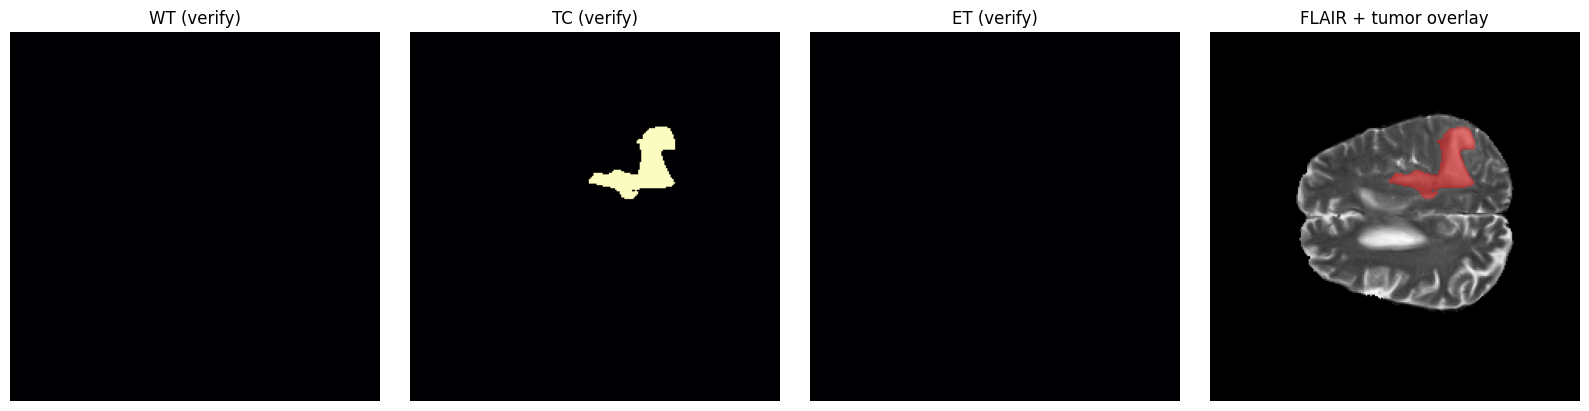

In [9]:
mask_names = ['WT (verify)', 'TC (verify)', 'ET (verify)'] if mask.shape[-1] == 3 else [f'Mask channel {i}' for i in range(mask.shape[-1])]
fig, axs = plt.subplots(1, mask.shape[-1]+1, figsize=(4*(mask.shape[-1]+1),4), constrained_layout=True)
for i in range(mask.shape[-1]):
    axs[i].imshow(mask[...,i], cmap='magma', vmin=0, vmax=1)
    axs[i].set_title(mask_names[i]); axs[i].axis('off')
axs[-1].imshow(image[...,3], cmap='gray')
axs[-1].imshow(np.ma.masked_where(~np.any(mask > 0, axis=-1), np.any(mask > 0, axis=-1)), cmap='autumn', alpha=.45)
axs[-1].set_title('FLAIR + tumor overlay'); axs[-1].axis('off')
plt.show()

## 7. Image dimensions and intensity statistics
Voxel spacing cannot be reliably recovered from these HDF5 slices unless stored as metadata.

In [10]:
rows=[]
for i,name in enumerate(MODALITIES):
    x=image[...,i].astype(np.float64)
    nz=x[x!=0]
    rows.append(dict(modality=name,height=x.shape[0],width=x.shape[1],min=x.min(),max=x.max(),mean=x.mean(),std=x.std(),nonzero_mean=nz.mean() if len(nz) else np.nan,nonzero_std=nz.std() if len(nz) else np.nan,nonzero_pct=100*np.mean(x!=0)))
display(pd.DataFrame(rows).round(4))

,modality,height,width,min,max,mean,std,nonzero_mean,nonzero_std,nonzero_pct
0,T1,240,240,-0.5103,6.5378,0.0,1.0,0.0,1.0,100.0
1,T1ce,240,240,-0.5542,2.6424,0.0,1.0,0.0,1.0,100.0
2,T2,240,240,-0.5581,7.0309,-0.0,1.0,-0.0,1.0,100.0
3,FLAIR,240,240,-0.5209,4.7419,0.0,1.0,0.0,1.0,100.0


## 8. Intensity histograms (nonzero pixels)

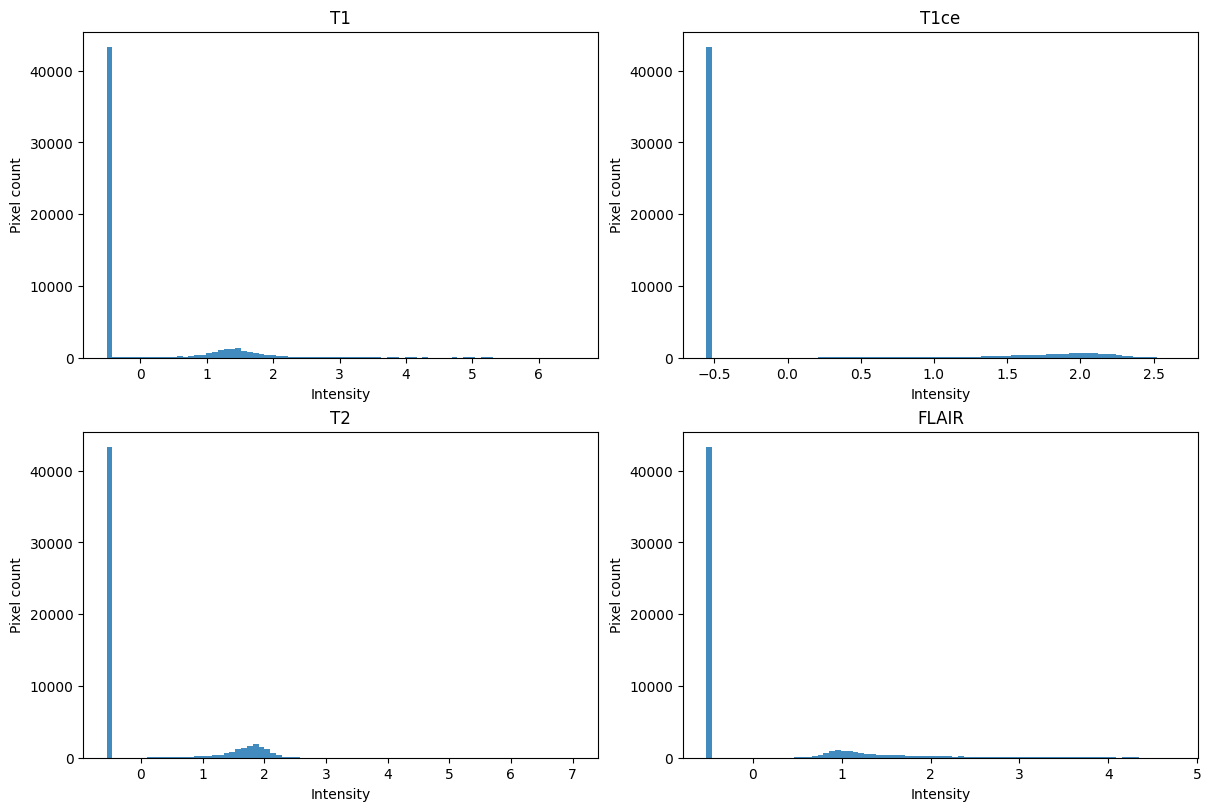

In [11]:
fig,axs=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for i,ax in enumerate(axs.flat):
    x=image[...,i].ravel(); x=x[x!=0]
    if len(x): ax.hist(x,bins=80,alpha=.85)
    ax.set_title(MODALITIES[i]); ax.set_xlabel('Intensity'); ax.set_ylabel('Pixel count')
plt.show()

## 9. Segmentation distribution and overlap
These masks may be nested/multilabel: do not treat channel counts as mutually exclusive classes.

In [12]:
mask_binary=mask>0
summary=pd.DataFrame([{'channel':mask_names[i], 'positive_pixels':int(mask_binary[...,i].sum()), 'positive_pct':round(100*mask_binary[...,i].mean(),3)} for i in range(mask.shape[-1])])
display(summary)
print('Union tumor pixels:',int(np.any(mask_binary,axis=-1).sum()))
print('Unique per-pixel channel combinations:',np.unique(mask_binary.reshape(-1,mask.shape[-1]).astype(int),axis=0))

,channel,positive_pixels,positive_pct
0,WT (verify),0,0.000
1,TC (verify),1111,1.929
2,ET (verify),0,0.000


Union tumor pixels: 1111
Unique per-pixel channel combinations: [[0 0 0]
 [0 1 0]]


## 10. Check a sample of the dataset
Inspect shape consistency and estimate tumor-positive fraction on a small sample, without loading every HDF5 slice into memory.

In [13]:
SAMPLE_SIZE=min(100,len(files))
sample_paths=[files[i] for i in np.linspace(0,len(files)-1,SAMPLE_SIZE,dtype=int)]
checks=[]
for p in sample_paths:
    try:
        x,y=load_slice(p)
        checks.append({'file':p.name,'image_shape':str(x.shape),'mask_shape':str(y.shape),'tumor_present':bool(np.any(y>0))})
    except Exception as e:
        checks.append({'file':p.name,'error':str(e)})
check_df=pd.DataFrame(checks)
display(check_df.head(10))
print('Sampled slices:',len(check_df))
print('Tumor-positive fraction:',check_df['tumor_present'].mean() if 'tumor_present' in check_df else 'N/A')
print('Image shapes:',check_df['image_shape'].value_counts().to_dict() if 'image_shape' in check_df else 'N/A')

,file,image_shape,mask_shape,tumor_present
0,volume_100_slice_0.h5,"(240, 240, 4)","(240, 240, 3)",False
1,volume_103_slice_60.h5,"(240, 240, 4)","(240, 240, 3)",True
2,volume_107_slice_22.h5,"(240, 240, 4)","(240, 240, 3)",False
3,volume_110_slice_123.h5,"(240, 240, 4)","(240, 240, 3)",True
4,volume_113_slice_86.h5,"(240, 240, 4)","(240, 240, 3)",True
5,volume_117_slice_48.h5,"(240, 240, 4)","(240, 240, 3)",True
6,volume_120_slice_149.h5,"(240, 240, 4)","(240, 240, 3)",False
7,volume_124_slice_110.h5,"(240, 240, 4)","(240, 240, 3)",False
8,volume_127_slice_73.h5,"(240, 240, 4)","(240, 240, 3)",True
9,volume_130_slice_35.h5,"(240, 240, 4)","(240, 240, 3)",True


Sampled slices: 100
Tumor-positive fraction: 0.42
Image shapes: {'(240, 240, 4)': 100}


## 11. Save an exploration summary
Kaggle outputs go to `/kaggle/working/`.

In [14]:
OUT=Path('/kaggle/working/neuroadapt_exploration');OUT.mkdir(parents=True,exist_ok=True)
pd.DataFrame(rows).to_csv(OUT/'modality_statistics.csv',index=False)
summary.to_csv(OUT/'mask_distribution.csv',index=False)
check_df.to_csv(OUT/'sample_checks.csv',index=False)
print('Saved summaries to:',OUT)

Saved summaries to: /kaggle/working/neuroadapt_exploration


## Next steps
1. Verify MRI and mask channel ordering against the dataset description.
2. Split by **volume/patient ID**, never randomly by slice, to avoid train/test leakage.
3. Implement `src/data/dataset.py` for HDF5 slices.
4. Build a 2D U-Net baseline before adaptive modality fusion.

**Limitations:** These files are preprocessed 2D slices; original 3D geometry, spacing and full-volume metadata may be unavailable.